In [125]:
import numpy as np

rng = np.random.default_rng(seed=1010)

In [227]:
class Setup: # we setup this parent class as the other integration proccesses use the same logic 
    def __init__(self, function, start, end, points):
        self.function = function
        self.start = start
        self.end = end
        self.xs = np.linspace(start, end, points)
        self.ys = self.function(self.xs)
        self.dx = (end-start)/(points-1)

    def calculate(self):
        return self.weights*self.function(self.xs)
        
    def signed(self):
        signed_area = np.sum(self.calculate())
        print(f"Signed Area: {signed_area}")
        return signed_area
    
    def total(self):
        total_area = np.sum(np.abs(self.calculate()))
        print(f"Total Area: {total_area}")
        return total_area

class Trapezoid(Setup):
    def __init__(self, function, start, end, points):
        super().__init__(function, start, end, points)
        coefficients = np.ones(points); coefficients[0], coefficients[-1] = 0.5, 0.5
        self.weights = self.dx*coefficients
    
class SimpsonThird(Setup):
    def __init__(self, function, start, end, points):
        if points % 2 != 1:
            raise ValueError("must be an odd number of points")
        super().__init__(function, start, end, points)
        coefficients = [4 if i%2 == 1 else 2 for i in range(points)] # set odd indices to 4, set even indeces to 2
        coefficients[0], coefficients[-1] = 1, 1
        self.weights = (self.dx/3)*np.array(coefficients)
    
class SimpsonEight(Setup):
    def __init__(self, function, start, end, points):
        if (points-1) % 3 != 0:
            raise ValueError("(points-1) must be a multiple of three")
        super().__init__(function, start, end, points)
        coefficients = [2 if i%3 == 0 else 3 for i in range(points)] # set every third indices to 2, otherwise set it as 3
        coefficients[0], coefficients[-1] = 1, 1
        self.weights = (3*self.dx/8)*np.array(coefficients)

class MonteCarlo(Setup):
    def __init__(self, function, start, end, points):
        super().__init__(function, start, end, points)
        self.xr = rng.uniform(start, end, points)

        # we want to find the max of the orig func
        ys_min, ys_max = min(np.min(self.ys), 0), max(np.max(self.ys), 0)
        
        # evaluate f at random points
        self.fxr = self.function(self.xr)
        self.yr = rng.uniform(ys_min, ys_max, points) # we obtain random y coordinates within the limits of the function

        box_area = (ys_max - ys_min) * (end - start) # we find the total area 

        # finding if the dots are within the curve and below/above axis
        above = np.where((0 <= self.yr) & (self.yr <= self.fxr), 1, 0)
        below = np.where((self.fxr <= self.yr) & (self.yr < 0), -1, 0)
        self.hits = above + below
        
        self.weights = box_area / points

    def calculate(self): # we redefine the way we calculate since we are using monte carlo hits
        return self.weights*self.hits
        

In [137]:
def func1(x):
    return np.sqrt(9 - (4*x**2))

def func2(x):
    return -x**2 + 1

def func3(x):
    return np.cos(x) * np.sqrt(x)

In [240]:
func = func3

t = Trapezoid(func, 0, 1.5, 100000)
t.signed()
t.total()

st = SimpsonThird(func, 0, 1.5, 100001)
st.signed()
st.total()

se = SimpsonEight(func, 0, 1.5, 1000000)
se.signed()
se.total()

m = MonteCarlo(func, 0, 1.5, 10000000)
m.signed()
m.total()

Signed Area: 0.7009457403813912
Total Area: 0.7009457403813912
Signed Area: 0.7009457477646359
Total Area: 0.7009457477646359
Signed Area: 0.7009457522994443
Total Area: 0.7009457522994443
Signed Area: 0.7008518073410863
Total Area: 0.7008518073410863


np.float64(0.7008518073410863)

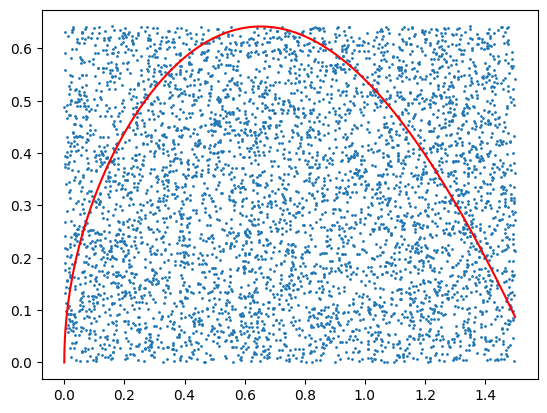

In [241]:
import matplotlib.pyplot as plt

#hits
#miss = np.where(

plt.scatter(m.xr[::2000], m.yr[::2000], s = 1)
plt.plot(m.xs[::2000], m.ys[::2000], c='red')

In [ ]:
def trapezoid(function, start, end, points):
    weights = np.ones(points)
    weights[0], weights[-1] = 0.5, 0.5

1. $y = \sqrt{9 - 4x^2}, \quad x\in[0,\frac{3}{2}]$
2. $y = -x^2 +1, \quad x\in[-2,2]$
3. $y = cos(x) \sqrt{x}, \quad x\in[0,\pi]$

In [135]:
xs = rng.uniform(1, 10, 10)
print(xs)

[6.40312488 2.43453763 6.22354436 2.56155076 4.90062309 4.11091175
 8.5302262  9.35742132 8.56591588 2.57016035]
